# 02 · Exploratory analysis: how do child and adult networks differ?

**Goal:** describe *how* connectivity differs between children and adults, and test **H2** (local → distributed organisation).

For each person we correlate every pair of the 39 regions: 39 × 38 / 2 = **741 connections**, a "wiring fingerprint". Then we compare the average child with the average adult at three levels: connections → networks → whole brain.

*Requires the outputs of notebook 01 in `data/`.*

In [1]:
# --- Setup -------------------------------------------------------------------
# Running on Google Colab? First run, in a new cell:
#   !git clone https://github.com/Leena2403/Brain_Network_Development_fMRI.git
#   %cd Brain_Network_Development_fMRI/notebooks
#   !pip install -q -r ../requirements.txt
import sys
sys.path.append("..")   # so we can import our own code from ../src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from nilearn import plotting

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"child": "#E69F00", "adult": "#0072B2"}   # colour-blind-safe orange / blue
DATA_DIR = "../data"                # intermediate files (not committed to git)
FIG_DIR = "../results/figures"      # figures used in the README

def save(name):
    """Save the current figure for the README."""
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

In [2]:
from src.feature_extraction import load_atlas

# Outputs of notebook 01
pheno = pd.read_csv(f"{DATA_DIR}/participants_clean.csv")
saved = np.load(f"{DATA_DIR}/time_series_msdl.npz", allow_pickle=True)
time_series = list(saved["time_series"])
assert list(saved["ids"]) == list(pheno["participant_id"]), "Rerun notebook 01"

atlas_maps, labels, networks, coords = load_atlas()
is_child = (pheno["Child_Adult"] == "child").values
y = (~is_child).astype(int)   # 0 = child, 1 = adult

print(f"{len(time_series)} participants ({is_child.sum()} children, {(~is_child).sum()} adults), "
      f"{time_series[0].shape[0]} time points x {time_series[0].shape[1]} regions each")

120 participants (88 children, 32 adults), 168 time points x 39 regions each


## 1. Connectivity matrices

We average correlations in **Fisher-z** space: correlations are bounded at ±1, so averaging them directly is biased. `arctanh` puts them on an unbounded scale where averaging is valid, and `tanh` converts back.

In [3]:
from src.feature_extraction import connectivity_matrices, fisher_z, group_mean

corr_mats = connectivity_matrices(time_series, kind="correlation")   # (people, 39, 39)
z_mats = fisher_z(corr_mats)
mean_child = group_mean(corr_mats, is_child)
mean_adult = group_mean(corr_mats, ~is_child)
print("Matrices:", corr_mats.shape)

Matrices: (120, 39, 39)


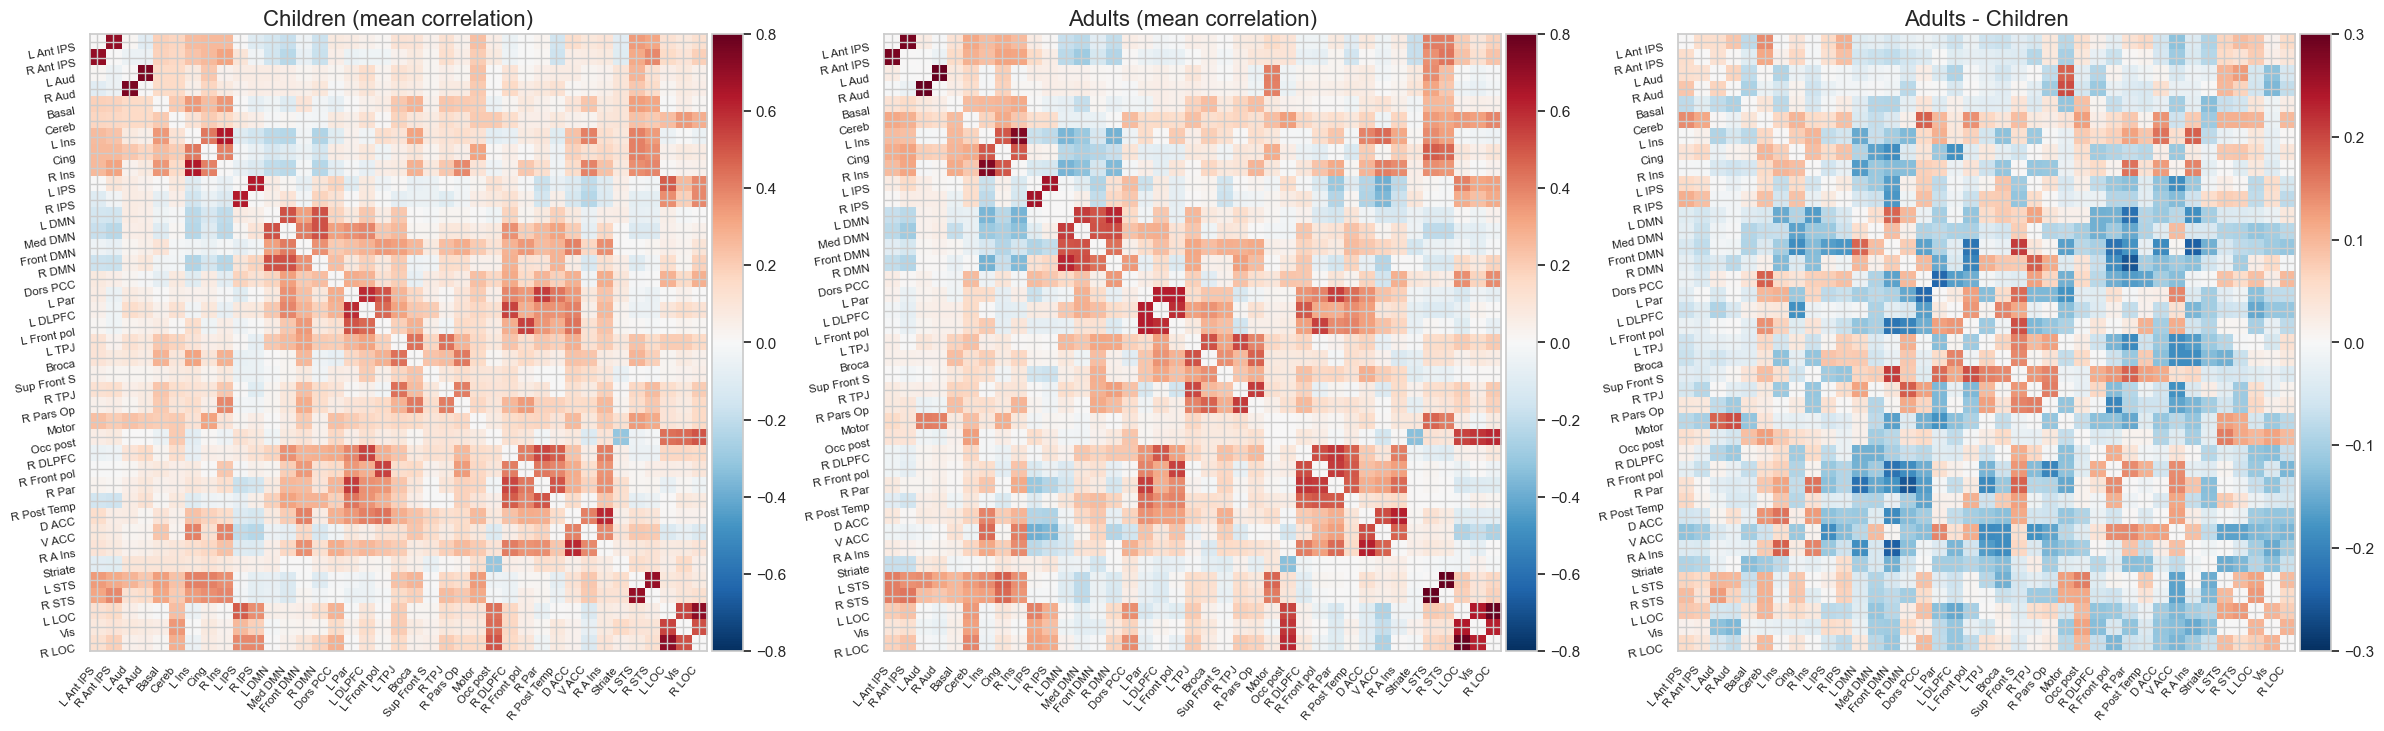

In [4]:
order = np.argsort(networks, kind="stable")   # sort regions by network so blocks are visible

def show_matrix(mat, title, vmax, ax):
    m = mat.copy()
    np.fill_diagonal(m, 0)   # hide self-connections (always 1)
    plotting.plot_matrix(m[np.ix_(order, order)], labels=list(labels[order]),
                         vmin=-vmax, vmax=vmax, axes=ax, title=title, colorbar=True)

fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))
show_matrix(mean_child, "Children (mean correlation)", 0.8, axes[0])
show_matrix(mean_adult, "Adults (mean correlation)", 0.8, axes[1])
show_matrix(mean_adult - mean_child, "Adults - Children", 0.3, axes[2])
plt.tight_layout(); save("02_connectivity_matrices"); plt.show()

**How to read it:** each square is one pair of regions; red = they rise and fall together, blue = opposite directions. Squares along the diagonal are connections within the same network. In the third panel, red = stronger in adults, blue = stronger in children.

**Insights**
- Children and adults share the **same basic layout**: the red blocks along the diagonal (networks) are already present in 3–12-year-olds.
- The difference panel is **mostly blue away from the diagonal** (62% of connections are weaker in adults) and **red near the diagonal**. Adults have stronger connections *inside* networks and weaker ones *between* networks.

## 2. Zoom out to networks
Average the 741 connections into blocks: within each network (diagonal) and between each pair of networks.

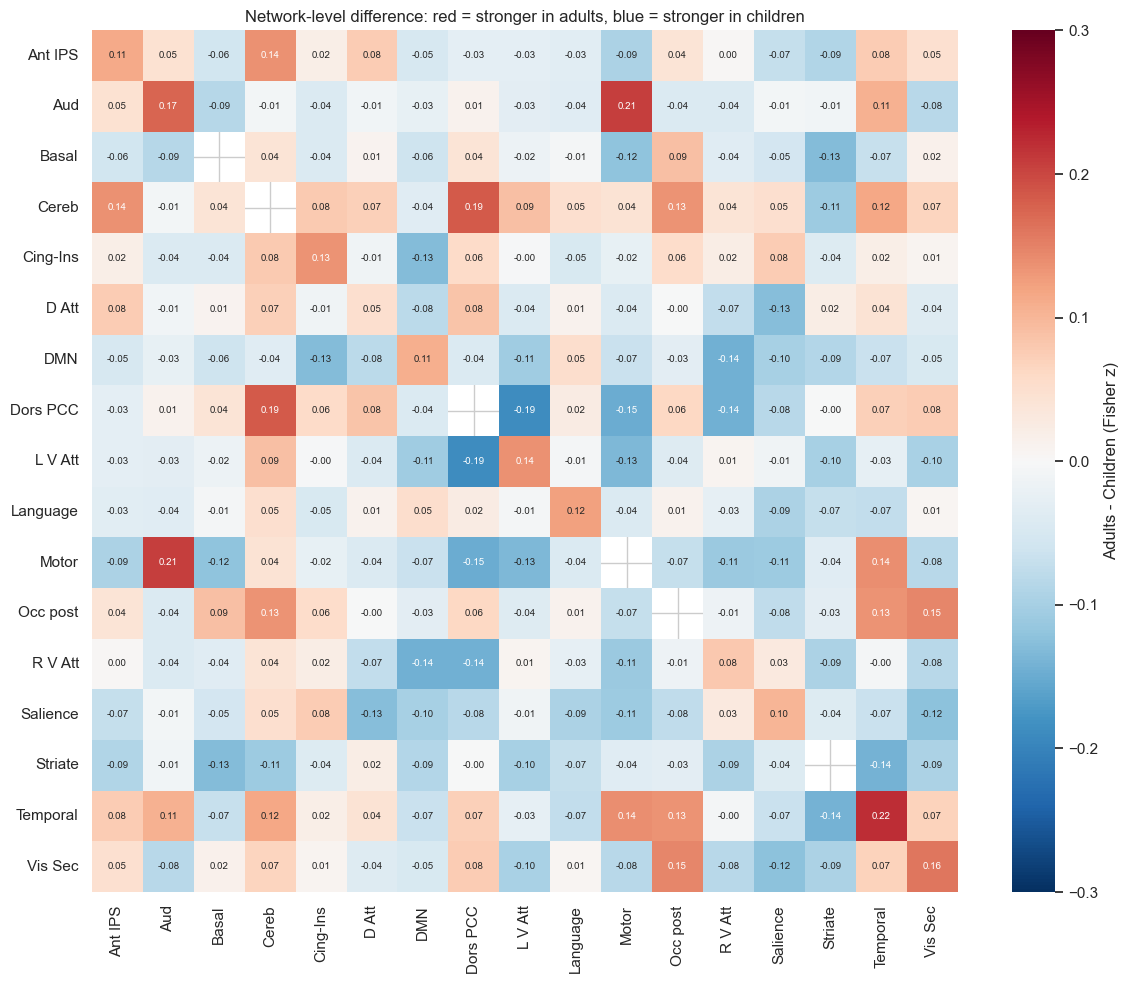

Within-network change (adults - children):
D Att       0.050
R V Att     0.081
Salience    0.101
DMN         0.109
Ant IPS     0.113
Language    0.123
Cing-Ins    0.135
L V Att     0.137
Vis Sec     0.161
Aud         0.175
Temporal    0.222


In [5]:
from src.feature_extraction import network_summary

net_names = list(dict.fromkeys(networks[order]))   # network names in plot order
net_diff = (network_summary(z_mats[~is_child].mean(0), networks, net_names)
            - network_summary(z_mats[is_child].mean(0), networks, net_names))

plt.figure(figsize=(12, 10))
sns.heatmap(net_diff, cmap="RdBu_r", center=0, vmin=-0.3, vmax=0.3, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "Adults - Children (Fisher z)"})
plt.title("Network-level difference: red = stronger in adults, blue = stronger in children")
plt.tight_layout(); save("02_network_differences"); plt.show()

within_diff = pd.Series(np.diag(net_diff), index=net_names).dropna().sort_values()
print("Within-network change (adults - children):")
print(within_diff.round(3).to_string())

**Insights**
- **Every** network with 2+ regions is more internally connected in adults (from +0.05 for dorsal attention to +0.22 for temporal). The largest gains are in temporal, auditory and secondary visual networks.
- Most off-diagonal blocks are blue: networks are **more separated** from each other in adults. The clearest case is the **default mode network (DMN)** decoupling from the attention and salience networks, a well-known feature of mature brain organisation.

## 3. Within- vs. between-network connectivity (H2)

H2 predicts that with age, regions in the same network become more tightly linked (**within ↑**) and networks become more distinct (**between ↓**). Each person becomes two numbers we can compare.

Because children still moved more after exclusion (notebook 01), we also fit a regression that **controls for mean FD**.

within_net   adult effect = +0.106 (p = 2.47e-07), FD effect = -0.245 (p = 0.0153)
between_net  adult effect = -0.020 (p = 0.0671), FD effect = +0.125 (p = 0.0293)


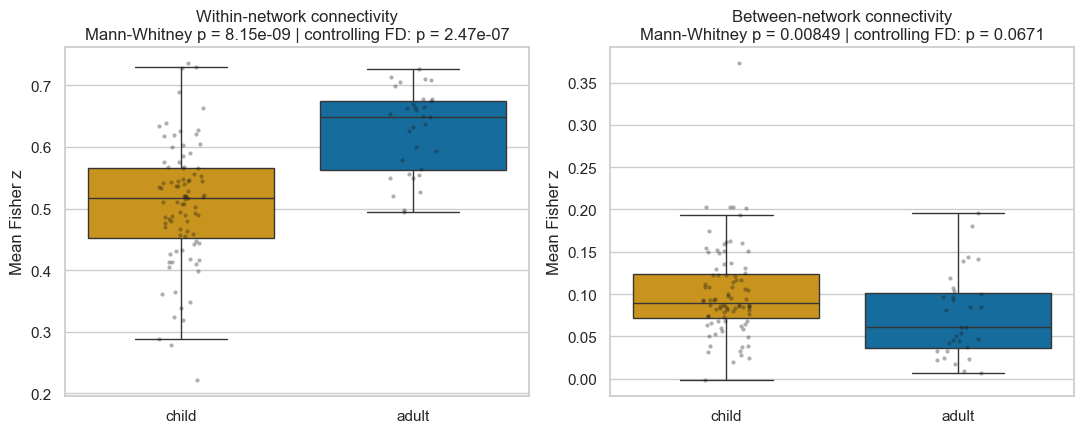

In [6]:
import statsmodels.formula.api as smf
from src.feature_extraction import within_between

pheno["within_net"], pheno["between_net"] = within_between(z_mats, networks)
pheno["adult"] = y

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, title in zip(axes, ["within_net", "between_net"],
                          ["Within-network connectivity", "Between-network connectivity"]):
    sns.boxplot(data=pheno, x="Child_Adult", y=col, hue="Child_Adult", palette=PALETTE,
                order=["child", "adult"], ax=ax, showfliers=False)
    sns.stripplot(data=pheno, x="Child_Adult", y=col, order=["child", "adult"],
                  color="k", alpha=0.35, size=3, ax=ax)
    p_raw = stats.mannwhitneyu(pheno.loc[is_child, col], pheno.loc[~is_child, col]).pvalue
    fit = smf.ols(f"{col} ~ adult + mean_fd", data=pheno).fit()
    ax.set(title=f"{title}\nMann-Whitney p = {p_raw:.3g} | controlling FD: p = {fit.pvalues['adult']:.3g}",
           xlabel="", ylabel="Mean Fisher z")
    print(f"{col:12s} adult effect = {fit.params['adult']:+.3f} (p = {fit.pvalues['adult']:.3g}), "
          f"FD effect = {fit.params['mean_fd']:+.3f} (p = {fit.pvalues['mean_fd']:.3g})")
plt.tight_layout(); save("02_within_between"); plt.show()

**Insights**
- **Within-network** connectivity is clearly higher in adults (median z 0.65 vs. 0.52; p = 8 × 10⁻⁹), and this **holds after controlling for motion** (p = 2 × 10⁻⁷).
- **Between-network** connectivity is slightly lower in adults (0.06 vs. 0.09; p = 0.008), but after controlling for motion it is only a trend (p = 0.067).
- Motion itself pushes in the *child-like* direction (more motion → lower within, higher between), which is exactly why the covariate is needed.

→ **H2, partly supported:** networks become more cohesive with age (robust); networks becoming more separate is weaker evidence.

## 4. Local → distributed? Connection length

Fair et al. (2009) found that, with age, **short-range** connections weaken and **long-range** connections strengthen. We test this directly: for each connection, compare the adult−child difference with the physical distance between the two regions.

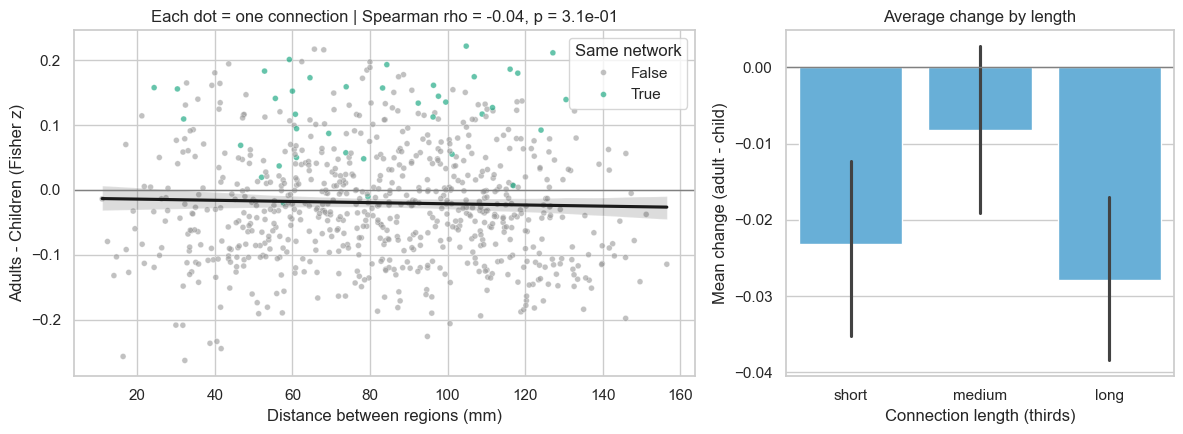

         mean  count
length              
short  -0.023    247
medium -0.008    247
long   -0.028    247


In [7]:
from src.feature_extraction import edge_table

edges = edge_table(labels, networks, coords)
rows, cols = np.tril_indices(len(labels), k=-1)
edges["diff_z"] = (z_mats[~is_child].mean(0) - z_mats[is_child].mean(0))[rows, cols]

rho = stats.spearmanr(edges.distance_mm, edges.diff_z)
edges["length"] = pd.qcut(edges.distance_mm, 3, labels=["short", "medium", "long"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.scatterplot(data=edges, x="distance_mm", y="diff_z", hue="same_network",
                palette={True: "#009E73", False: "#999999"}, alpha=0.6, s=18, ax=axes[0])
sns.regplot(data=edges, x="distance_mm", y="diff_z", scatter=False, color="k", ax=axes[0])
axes[0].axhline(0, c="gray", lw=1)
axes[0].set(xlabel="Distance between regions (mm)", ylabel="Adults - Children (Fisher z)",
            title=f"Each dot = one connection | Spearman rho = {rho.statistic:.2f}, p = {rho.pvalue:.1e}")
axes[0].legend(title="Same network")
sns.barplot(data=edges, x="length", y="diff_z", color="#56B4E9", ax=axes[1])
axes[1].axhline(0, c="gray", lw=1)
axes[1].set(xlabel="Connection length (thirds)", ylabel="Mean change (adult - child)",
            title="Average change by length")
plt.tight_layout(); save("02_distance_effect"); plt.show()

print(edges.groupby("length", observed=True).diff_z.agg(["mean", "count"]).round(3))

*Note: the 741 connections are not independent (they share regions), so treat the p-value as descriptive; the direction and size of the trend are what matter.*

**Insight:** there is **no relationship between connection length and developmental change** (ρ = −0.04, p = 0.31). Short and long connections both become slightly weaker in adults on average. This does **not** replicate the "local → distributed" pattern of Fair et al. (2009). That is plausible: later work showed that much of the original distance effect was caused by head motion (Power et al., 2012; Satterthwaite et al., 2013), and our pipeline removes motion more strictly. MSDL regions are also large, so very short connections are rare.

What *does* predict change is **network membership** (green dots, mostly above 0), not distance.

## 5. The biggest differences on a brain

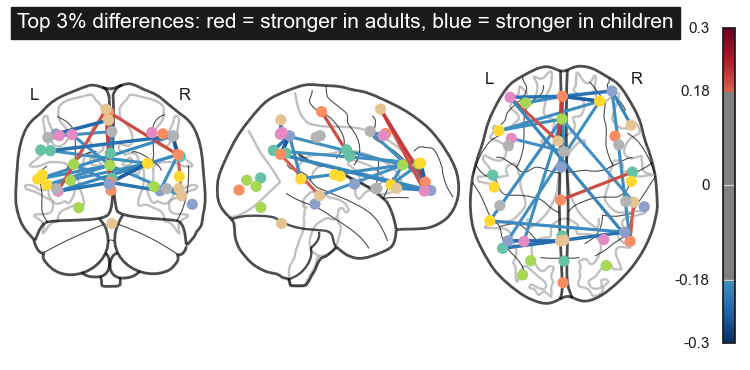

,region_A,network_A,region_B,network_B,same_network,distance_mm,diff_z,length
281,R A Ins,Salience,Front DMN,DMN,False,32.239,-0.263,short
61,R Par,R V Att,R DMN,DMN,False,16.310,-0.257,short
542,Dors PCC,Dors PCC,L Par,L V Att,False,41.604,-0.245,short
50,R Front pol,R V Att,Front DMN,DMN,False,38.723,-0.237,short
125,L Front pol,L V Att,Front DMN,DMN,False,40.507,-0.234,short
58,R Par,R V Att,L DMN,DMN,False,94.811,-0.226,medium
350,R STS,Temporal,L STS,Temporal,True,104.824,0.222,long
411,Sup Front S,Language,Front DMN,DMN,False,65.662,0.217,short
29,Motor,Motor,R Aud,Aud,False,68.072,0.216,medium
13,Front DMN,DMN,L DMN,DMN,True,127.181,0.212,long


In [8]:
diff = mean_adult - mean_child
np.fill_diagonal(diff, 0)
plotting.plot_connectome(diff, coords, edge_threshold="97%", edge_cmap="RdBu_r",
                         edge_vmin=-0.3, edge_vmax=0.3, colorbar=True,
                         title="Top 3% differences: red = stronger in adults, blue = stronger in children")
plt.show()

edges.reindex(edges.diff_z.abs().sort_values(ascending=False).index).head(10).round(3)

**Insights**
- **Biggest decreases** (blue): DMN ↔ salience/attention, e.g. right anterior insula ↔ frontal DMN and right parietal ↔ right DMN. Task-control regions *disconnect* from the DMN with age.
- **Biggest increases** (red): long-range links **within** a system, e.g. left ↔ right STS (temporal) and frontal ↔ lateral DMN. This matches the idea that the DMN becomes an integrated front-to-back network with age (Fair et al., 2008).

## Summary

| Question | Finding |
|---|---|
| Same overall layout? | Yes, networks are already visible in children |
| Within-network connectivity | **Higher in adults** (p < 10⁻⁶, survives motion control) |
| Between-network connectivity | Lower in adults, but only a trend once motion is controlled |
| Local → distributed (distance) | **Not found** (ρ = −0.04) |
| Clearest specific change | DMN decouples from salience/attention; long-range within-network links strengthen |

**H2:** the **segregation** part is supported (networks become more cohesive and more distinct). The **distance-based** "local → distributed" claim is not supported in this motion-controlled data.

**Next:** notebook 03 asks whether these differences are strong enough to classify individual people (H1) and whether motion explains it (H3).